In [1]:
from all_stable import *
import pandas as pd
from tqdm import tqdm
import ast
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import pandas as pd
from tqdm import tqdm
import ast
import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
import numpy as np


def anna_find_all_stable(malechoice, femalechoice, n):
    # Output list with all matchings
    res = []
    # Initialization
    unchanged = [True] * n
    marriage = [0] * n
    malecounter = [0] * n
    # Female choice transformation

    fc = np.zeros((n, n), dtype=int)
    for i in range(0, n):
        for j in range(0, n):
            fc[i][femalechoice[i][j]] = j
        fc[i][0] = n
        malecounter[i] = 0
        marriage[i] = 0

    def get_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        return(malematches)

    def print_marriage(marriage):
        malematches = [0] * (n)
        for j in range(0, n):
            malematches[marriage[j] - 1] = j
        print(*malematches)

    def proposal(i, malec, marriage, c):
        if i < 0:
            success = True
        elif (i == 0) or malec[i] == (n - 1) or not (unchanged[i]):  # n not (n+1), as we have n equals 5
            success = False
        else:
            c += 1
            j = malec[i]
            malec[i] = j + 1
            success = refusal(i, malechoice[i][j], malec, marriage, c)
        return success

    def refusal(i, j, malec, marriage, c):
        if fc[j][abs(marriage[j])] > fc[j][i]:
            k = marriage[j]
            marriage[j] = i
            success = proposal(k, malec, marriage, c)
        else:
            success = proposal(i, malec, marriage, c)
        return success

    def breakmariage(malecounter, marriage, i, n, count):
        malecounter_ori = malecounter.copy()
        marriage_ori = marriage.copy()
        marriage[malechoice[i][malecounter[i] - 1]] = -i
        success = proposal(i, malecounter, marriage, count)

        if not (success):
            unchanged[i] = False
            malecounter_ref = malecounter_ori.copy()
            marriage_ref = marriage_ori.copy()
            malecounter = malecounter_ref
            marriage = marriage_ref
            return malecounter, marriage

        #print_marriage(marriage)  # marriage[i] means the woman who is married to i man
        new_marriage = get_marriage(marriage)  # convert into female solution
        res.append(new_marriage)
        # establish the relationships between the original and the obtained stable matching

        for j in range(i, n):
            # if i==2 and j==2:
            #     print("This is it")
            malecounter, marriage = breakmariage(malecounter, marriage, j, n, count)

        for j in range((i + 1), n):
            unchanged[j] = True
        # return malecounter_ori, abs(marriage_ori)
        return malecounter_ori, marriage_ori

    count = 0
    for i in range(0, n):
        proposal(i, malecounter, marriage, count)
    #print_marriage(marriage)

    new_marriage = get_marriage(marriage)  # convert into female solution
    res.append(new_marriage)
    # establish the relationships between the original and the obtained stable matching

    M_optimal_marriage = marriage.copy()
    M_optimal_counter = malecounter.copy()
    for i in range(0, n):
        breakmariage(M_optimal_counter.copy(), M_optimal_marriage.copy(), i, n, count)
    return res


**Mallows**

In [32]:
df = pd.read_csv("mallows_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("mallows_gain_test.csv", index=False)


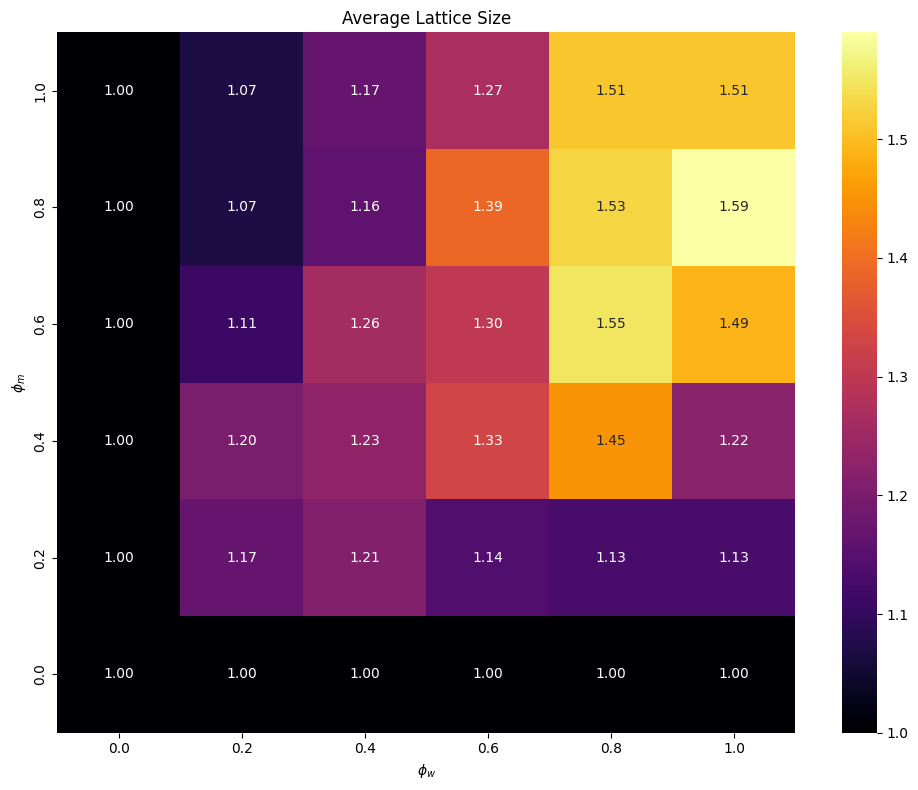

In [33]:

# Load the CSV with stability counts
df = pd.read_csv("mallows_gain_test.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["stability_count"]
    .mean()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_lattice_10.pdf")
plt.show()


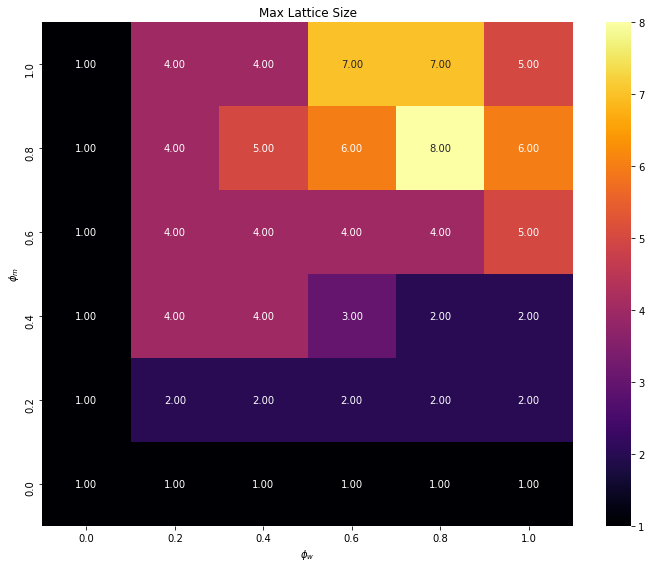

In [6]:

# Load the CSV with stability counts
df = pd.read_csv("mallows_gain.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["stability_count"]
    .max()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Max Lattice Size")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Mallows MD**

In [34]:
df = pd.read_csv("mallows_MD_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("mallows_MD_gain_test.csv", index=False)



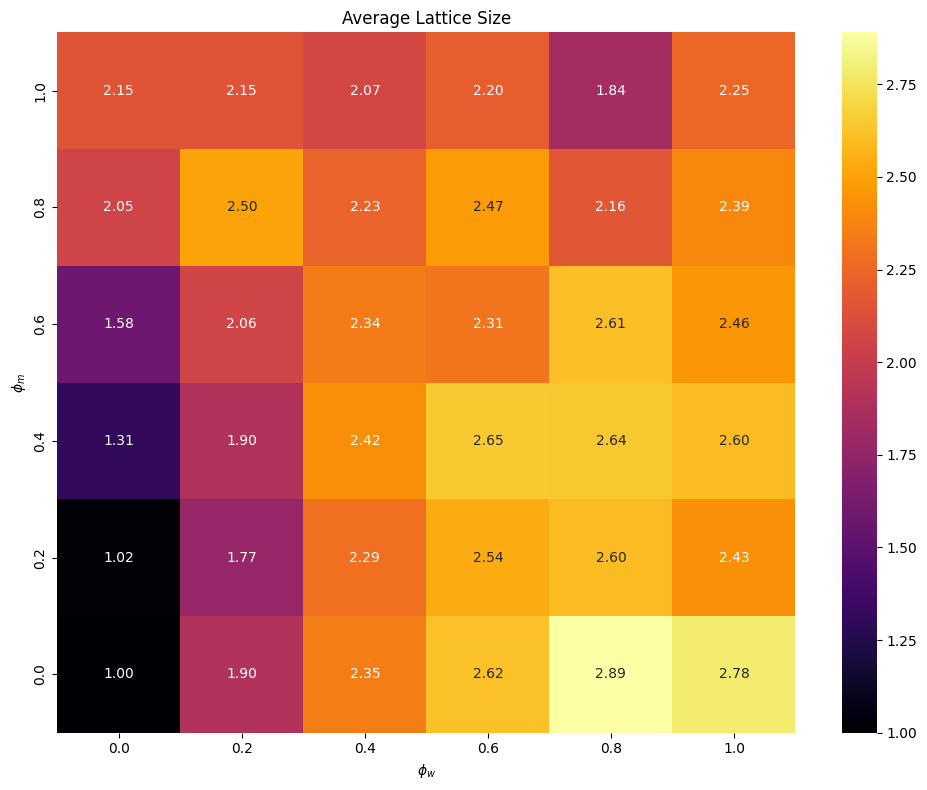

In [63]:

# Load the CSV with stability counts
df = pd.read_csv("mallows_MD_gain.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["stability_count"]
    .mean()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Mallows MA**

In [37]:
df = pd.read_csv("mallows_MA_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("mallows_MA_gain_test.csv", index=False)



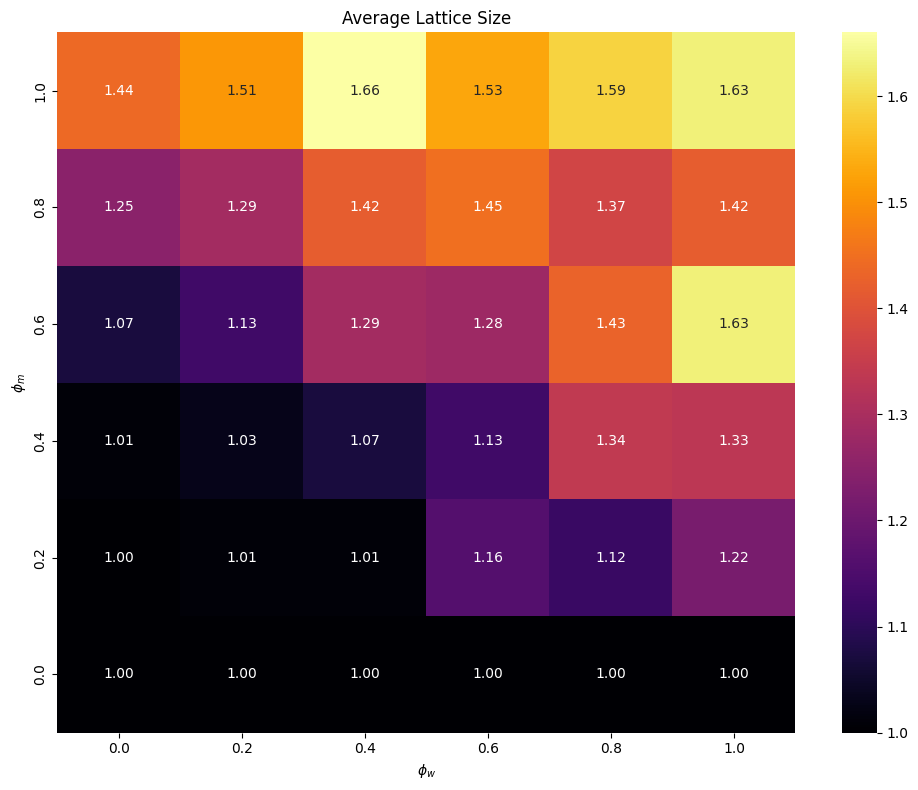

In [38]:

# Load the CSV with stability counts
df = pd.read_csv("mallows_MA_gain_test.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["stability_count"]
    .mean()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.savefig("mallows_MA_avg_lattice_size.pdf")
plt.show()


**Mallows Euclidean**

In [ ]:
df = pd.read_csv("mallows_euclidean_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("mallows_euclidean_gain_test.csv", index=False)



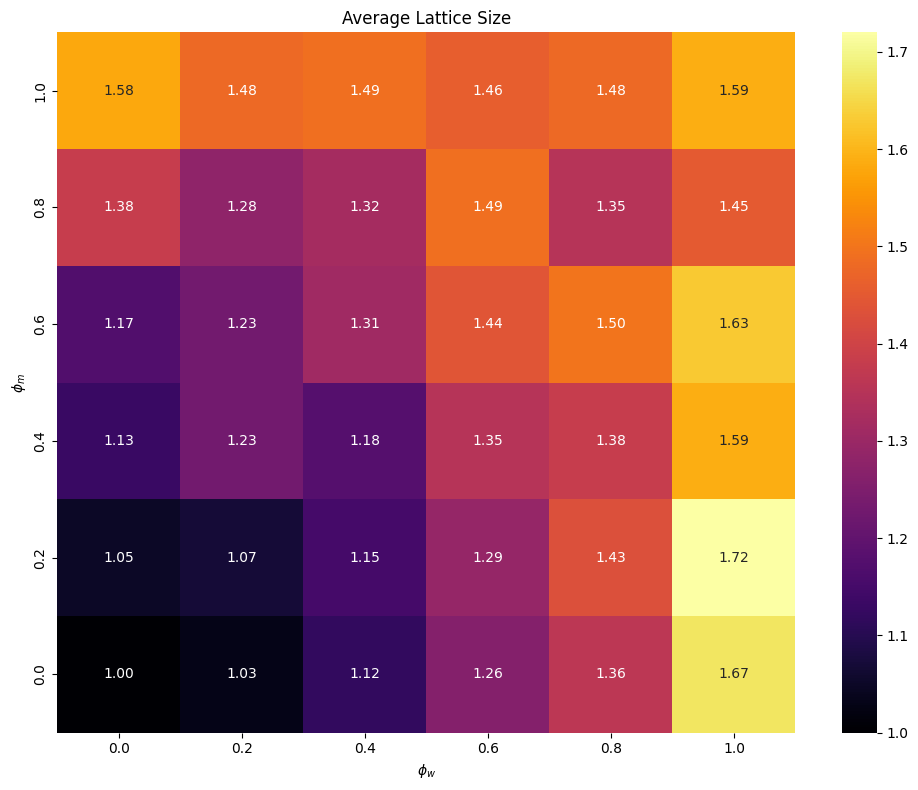

In [40]:

# Load the CSV with stability counts
df = pd.read_csv("mallows_euclidean_gain_test.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["phi_m", "phi_w"])["stability_count"]
    .mean()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="phi_m", columns="phi_w", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel(r"$\phi_w$")
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Reverse Euclidean**

In [61]:
df = pd.read_csv("reverse_euclidean_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("reverse_euclidean_gain_test.csv", index=False)



In [39]:
df = pd.read_csv("reverse_euclidean_gain.csv")
stability_counts = []
for idx in range(1000):
    row  = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"])
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    stable = find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)
print(stability_counts)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 2, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 3, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 2, 1, 1, 3, 1, 2, 1, 2, 1, 1, 1, 2, 1, 2, 3, 2, 1, 1, 1, 1, 3, 4, 3, 3, 1, 2, 3, 4, 1, 2, 1, 2, 1, 2, 1, 1, 3, 3, 3, 1, 1, 1, 2, 4, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 3, 1, 2, 2, 2, 4, 1, 1, 1, 2, 2, 3, 2, 2, 1, 1, 1, 1, 2, 1, 2, 2, 1, 1, 2, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 3, 1, 2, 1, 1, 1, 2, 2, 3, 3, 1, 1, 1, 1, 1, 3, 1, 3, 1, 1, 2, 1, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 2, 2, 3, 1, 2, 2, 1, 1, 3, 2, 4, 1, 2, 1, 1, 2, 2, 1, 1, 1, 2, 1, 1, 2, 2, 1, 2, 2, 2, 2, 1, 1, 1, 2, 6, 2, 1, 1, 5, 2, 3, 2, 1, 1, 1, 1, 3, 3, 1, 1, 3, 1, 1, 2, 1, 2, 3, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 3, 2, 1, 1, 3, 2, 2, 1, 1, 1, 1, 2, 2, 1, 5, 1, 3, 1, 2, 2, 

In [27]:
df = pd.read_csv("reverse_euclidean_gain.csv")
stability_counts = []
idx = 17
row  = df.loc[idx]
mpref, wpref = ast.literal_eval(row["preferences"])
m_pref = [[int(x) for x in sublist] for sublist in mpref]
w_pref = [[int(x) for x in sublist] for sublist in wpref]
mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
print(mpref,wpref)
stable = anna_find_all_stable(mpref, wpref,len(mpref))
num_stable = len(stable)
stability_counts.append(num_stable)
print(stable)

[[5, 3, 4, 7, 9, 0, 6, 2, 1, 8], [0, 5, 8, 4, 7, 3, 2, 6, 1, 9], [0, 5, 8, 2, 6, 3, 1, 4, 9, 7], [5, 3, 4, 7, 9, 6, 0, 2, 1, 8], [4, 7, 8, 0, 3, 5, 1, 9, 2, 6], [4, 7, 3, 9, 5, 1, 6, 2, 8, 0], [0, 8, 5, 2, 6, 1, 7, 3, 9, 4], [5, 0, 3, 6, 2, 8, 4, 9, 7, 1], [0, 8, 5, 2, 6, 1, 7, 4, 9, 3], [4, 7, 3, 1, 9, 8, 5, 6, 2, 0]] [[8, 6, 2, 7, 1, 3, 4, 0, 9, 5], [5, 9, 3, 8, 6, 4, 0, 7, 2, 1], [8, 7, 3, 6, 2, 5, 9, 0, 1, 4], [5, 3, 9, 0, 7, 4, 1, 2, 6, 8], [5, 9, 3, 0, 4, 7, 1, 8, 2, 6], [3, 7, 0, 5, 2, 6, 8, 1, 9, 4], [3, 7, 5, 8, 6, 2, 9, 0, 1, 4], [5, 9, 3, 0, 4, 1, 8, 7, 6, 2], [8, 6, 2, 9, 4, 7, 1, 5, 3, 0], [5, 3, 9, 7, 0, 8, 6, 2, 4, 1]]
[[6, 2, 5, 1, 4, 8, 3, 0, 7, 9]]


In [59]:
df = pd.read_csv("reverse_euclidean_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    m_pref, w_pref = ast.literal_eval(row["preferences"])
    #m_pref = [[]] + [[int(x) for x in sublist] for sublist in mpref]
    #w_pref = [[]] + [[int(x) for x in sublist] for sublist in wpref]

    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("reverse_euclidean_gain_test2.csv", index=False)

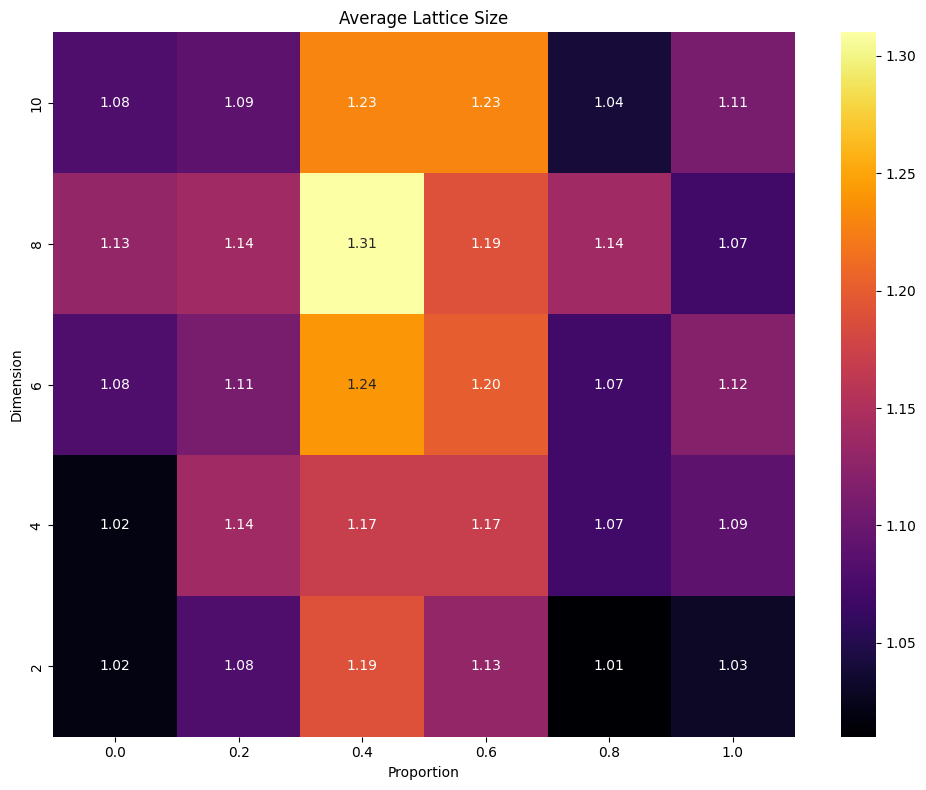

In [64]:

# Load the CSV with stability counts
df = pd.read_csv("reverse_euclidean_gain_test2.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["dimension", "proportion"])["stability_count"]
    .mean()
    .reset_index()
)
# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="dimension", columns="proportion", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


In [13]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('reverse_euclidean_gain.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    stable_matchings = find_all_stable(mpref, wpref, len(mpref))
    print(stable_matchings)
    num_stable_matchings = len(stable_matchings)

    stable_lst.append(num_stable_matchings)

    
    dimension = df.loc[idx, 'dimension']
    proportion = df.loc[idx, 'proportion']
    
    stable_matchings_count[(dimension, proportion)].append(num_stable_matchings)
df['number_of_stable_matchings'] = stable_lst
#df.to_csv('reverse_euclidean_test.csv', index=False)

averages = {
    (dimension, proportion): sum(counts) / len(counts)
    for (dimension, proportion), counts in stable_matchings_count.items()}

for (dimension, proportion), avg in sorted(averages.items()):
    print(f"dimension: {dimension}, proportion: {proportion} -> Average Stable Matchings: {avg:.2f}")

print(averages)


[[8, 7, 2, 6, 5, 9, 3, 1, 4]]
[[8, 6, 7, 3, 5, 9, 1, 2, 4]]
[[5, 8, 6, 7, 1, 4, 2, 9, 3]]
[[8, 4, 6, 1, 3, 5, 9, 7, 2]]
[[6, 4, 5, 2, 1, 3, 8, 9, 7]]
[[5, 6, 1, 9, 7, 3, 4, 8, 2]]
[[2, 3, 8, 6, 5, 7, 4, 1, 9]]
[[5, 6, 8, 7, 3, 1, 9, 4, 2]]
[[1, 7, 8, 5, 3, 6, 9, 4, 2]]
[[4, 2, 6, 3, 5, 1, 8, 9, 7]]
[[2, 1, 4, 5, 6, 8, 9, 7, 3]]
[[2, 9, 1, 6, 8, 5, 4, 7, 3]]
[[3, 8, 1, 7, 6, 9, 4, 5, 2]]
[[9, 4, 8, 1, 6, 3, 7, 2, 5]]
[[7, 9, 3, 4, 2, 1, 8, 6, 5]]
[[8, 2, 0, 6, 5, 4, 1, 9, 7]]
[[5, 3, 9, 1, 7, 4, 6, 8, 2]]
[[1, 6, 5, 9, 4, 2, 3, 8, 7], [1, 9, 5, 2, 4, 6, 3, 8, 7]]
[[8, 2, 3, 1, 9, 5, 4, 7, 6]]
[[0, 9, 1, 8, 5, 4, 2, 6, 7]]
[[6, 1, 9, 2, 8, 4, 3, 7, 5], [6, 1, 9, 8, 3, 4, 2, 7, 5]]
[[2, 8, 4, 1, 6, 5, 7, 9, 3]]
[[9, 3, 1, 5, 2, 7, 4, 8, 6]]
[[8, 7, 4, 9, 1, 5, 6, 2, 3]]
[[8, 0, 7, 9, 4, 1, 2, 5, 6]]
[[1, 3, 8, 0, 2, 7, 6, 9, 5]]
[[9, 3, 6, 7, 4, 2, 1, 8, 5]]
[[3, 5, 7, 4, 2, 1, 9, 8, 6]]
[[7, 5, 4, 1, 6, 2, 9, 8, 3]]
[[3, 4, 1, 2, 7, 5, 9, 8, 6]]
[[3, 6, 5, 4, 9, 2, 7, 1, 8]]
[[9, 5, 1, 4

In [ ]:
import pandas as pd
import json
from collections import defaultdict

df = pd.read_csv('reverse_euclidean_gain.csv')

stable_matchings_count = defaultdict(list)
stable_lst = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]
    stable_matchings = anna_find_all_stable(mpref, wpref, len(mpref))
    print(stable_matchings)
    num_stable_matchings = len(stable_matchings)

    stable_lst.append(num_stable_matchings)

    
    dimension = df.loc[idx, 'dimension']
    proportion = df.loc[idx, 'proportion']
    
    stable_matchings_count[(dimension, proportion)].append(num_stable_matchings)
df['number_of_stable_matchings'] = stable_lst
#df.to_csv('reverse_euclidean_test.csv', index=False)

averages = {
    (dimension, proportion): sum(counts) / len(counts)
    for (dimension, proportion), counts in stable_matchings_count.items()}

for (dimension, proportion), avg in sorted(averages.items()):
    print(f"dimension: {dimension}, proportion: {proportion} -> Average Stable Matchings: {avg:.2f}")

print(averages)


[[8, 0, 2, 6, 5, 7, 3, 1, 4, 9]]
[[0, 6, 8, 3, 5, 9, 1, 2, 4, 7]]
[[2, 0, 6, 7, 1, 4, 8, 9, 3, 5]]
[[8, 6, 5, 1, 3, 2, 9, 7, 0, 4]]
[[6, 4, 5, 2, 1, 9, 8, 0, 7, 3]]
[[5, 6, 1, 9, 7, 3, 4, 0, 2, 8]]
[[2, 3, 8, 6, 5, 7, 4, 1, 0, 9]]
[[0, 6, 7, 5, 3, 8, 9, 4, 2, 1]]
[[0, 7, 8, 5, 3, 6, 9, 4, 2, 1]]
[[4, 2, 6, 3, 5, 1, 8, 9, 7, 0]]
[[6, 1, 4, 5, 0, 8, 9, 7, 2, 3]]
[[2, 9, 1, 5, 8, 0, 4, 6, 3, 7]]
[[3, 8, 1, 7, 6, 9, 4, 0, 2, 5]]
[[9, 0, 1, 3, 6, 8, 7, 4, 5, 2]]
[[7, 2, 3, 4, 5, 1, 8, 6, 0, 9]]
[[8, 2, 4, 0, 5, 6, 1, 9, 7, 3]]
[[5, 0, 3, 1, 7, 4, 6, 8, 2, 9]]
[[6, 2, 5, 1, 4, 8, 3, 0, 7, 9]]
[[8, 5, 7, 0, 1, 4, 3, 6, 9, 2]]
[[0, 9, 1, 8, 5, 4, 2, 6, 7, 3]]
[[6, 1, 9, 2, 5, 0, 8, 7, 4, 3]]
[[0, 7, 4, 3, 8, 5, 2, 9, 6, 1]]
[[3, 0, 1, 5, 2, 9, 4, 8, 6, 7]]
[[0, 7, 4, 9, 1, 5, 6, 2, 3, 8]]
[[8, 9, 7, 3, 4, 1, 2, 5, 0, 6]]
[[9, 1, 8, 3, 2, 7, 6, 0, 5, 4]]
[[9, 3, 6, 7, 4, 2, 1, 0, 8, 5]]
[[4, 5, 7, 0, 2, 1, 9, 8, 6, 3]]
[[4, 5, 7, 1, 0, 2, 9, 8, 3, 6]]
[[3, 4, 0, 2, 7, 1, 9, 8, 6, 5]]
[[3, 0, 5,

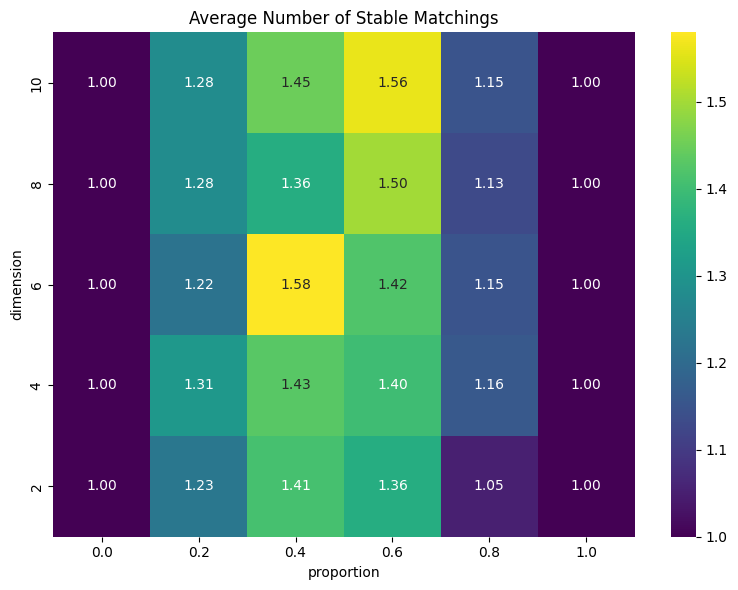

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

dimension = list(sorted(df['dimension'].unique()))
proportion = list(sorted(df['proportion'].unique()))

dimension_index = {d: i for i, d in enumerate(dimension)}
proportion_index = {p: i for i, p in enumerate(proportion)}

heatmap_data = np.zeros((len(dimension), len(proportion)))

for (dim, prop), avg in averages.items():
    i = dimension_index[dim]
    j = proportion_index[prop]
    heatmap_data[i][j] = avg

plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".2f",
            xticklabels=proportion, yticklabels=dimension, cmap="viridis")
plt.gca().invert_yaxis()  
plt.title("Average Number of Stable Matchings")
plt.xlabel("proportion")
plt.ylabel("dimension")
plt.tight_layout()
plt.savefig("stability_reverse_euclidean.pdf", format='pdf')
plt.show()


**Expectations Euclidean**

In [41]:
df = pd.read_csv("expectations_euclidean_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("expectations_euclidean_gain_test.csv", index=False)



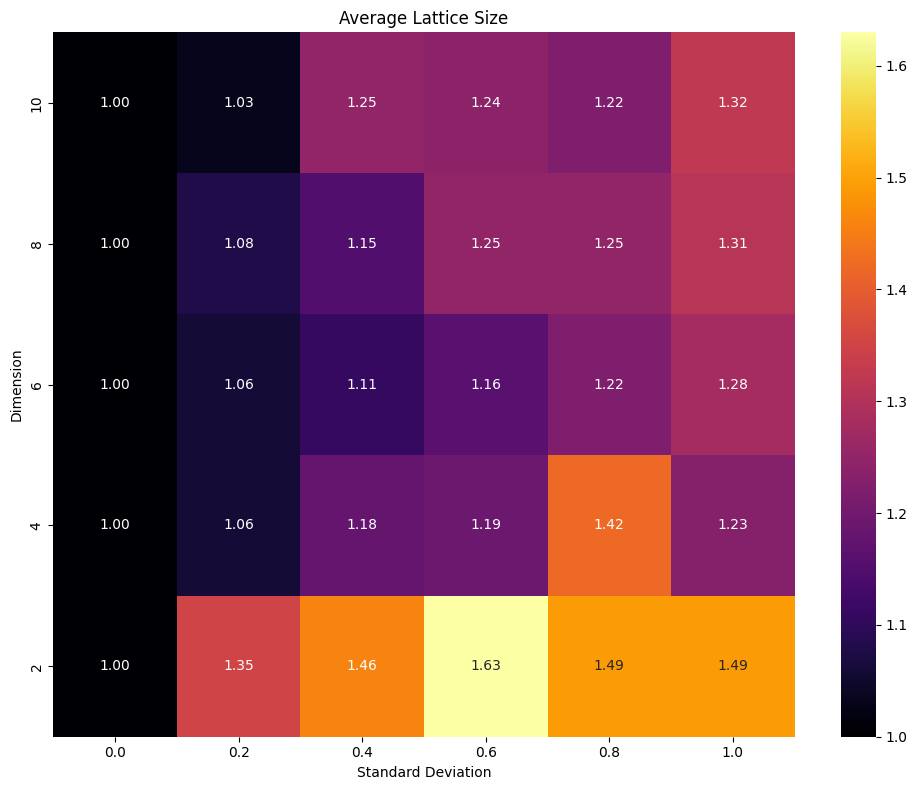

In [42]:

# Load the CSV with stability counts
df = pd.read_csv("expectations_euclidean_gain_test.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["dimension", "std"])["stability_count"]
    .mean()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="dimension", columns="std", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


**Fame Euclidean**

In [43]:
df = pd.read_csv("fame_euclidean_gain.csv")

stability_counts = []

for idx in range(len(df)):
    row = df.loc[idx]
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    m_pref = [[int(x) for x in sublist] for sublist in mpref]
    w_pref = [[int(x) for x in sublist] for sublist in wpref]
    mpref = [[int(x)-1 for x in sublist] for sublist in m_pref]
    wpref = [[int(x)-1 for x in sublist] for sublist in w_pref]

    stable = anna_find_all_stable(mpref, wpref, len(mpref))
    num_stable = len(stable)
    stability_counts.append(num_stable)

df["stability_count"] = stability_counts
df.to_csv("fame_euclidean_gain_test.csv", index=False)



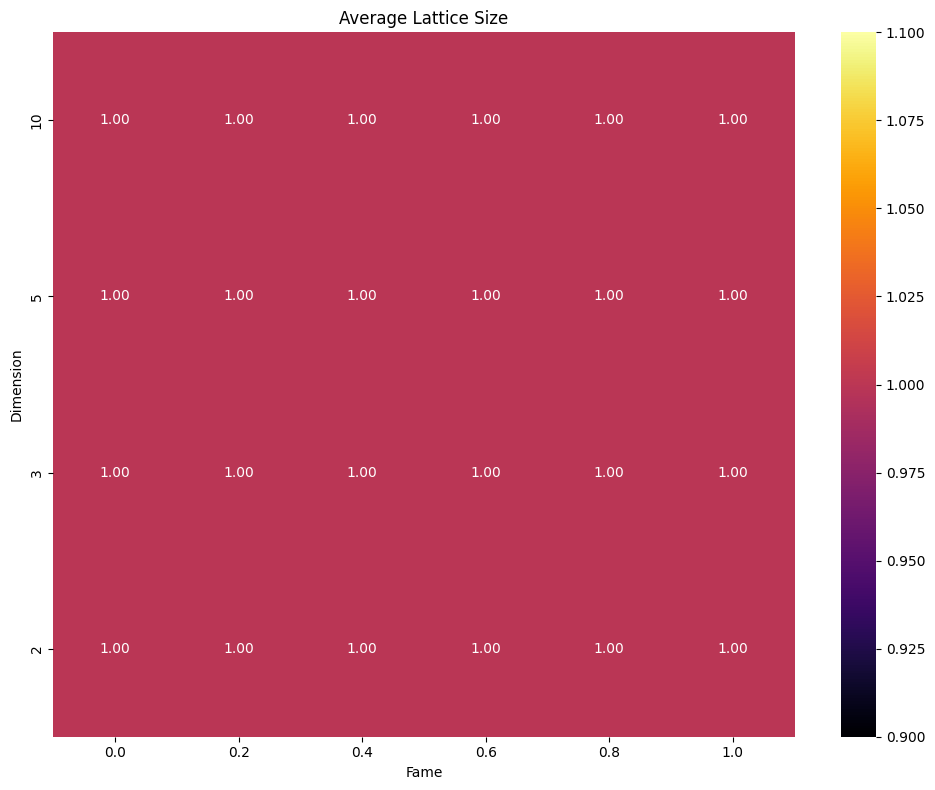

In [44]:

# Load the CSV with stability counts
df = pd.read_csv("fame_euclidean_gain_test.csv")

# Group by phi_m and phi_w and compute the average number of stable matchings
heatmap_data = (
    df.groupby(["dimension", "fame"])["stability_count"]
    .mean()
    .reset_index()
)

# Pivot into matrix form for heatmap
heatmap_matrix = heatmap_data.pivot(index="dimension", columns="fame", values="stability_count")

# Sort the axis values numerically (optional, but often helpful)
heatmap_matrix = heatmap_matrix.sort_index(axis=0).sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="inferno")
plt.title("Average Lattice Size")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()
